# Imports

In [3]:
import os
from typing import List, Tuple, Dict, Callable, Optional, Type
import math
import re

from PIL import Image
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision.transforms import v2

# Data loading

## Description

+ 89.400 JPEG images
+ 16 $\times$ 16 pixels, RGB (16 $\cdot$ 16 $\cdot$ 3 = 768)
+ Classes:
    + 0: Hero
    + 1: Non-hero
    + 2: Food
    + 3: Spell/Weapon
    + 4: Side-facing

## Data variables

In [4]:
BASE_DIR_NAME = "archive"
IMAGE_DIR_NAME = "images"
TABLE_FILE_NAME = "labels.csv"

IMAGE_DIR = os.path.join(BASE_DIR_NAME, IMAGE_DIR_NAME)
TABLE_FILE = os.path.join(BASE_DIR_NAME, TABLE_FILE_NAME)

table = pd.read_csv(TABLE_FILE)

## Image checking

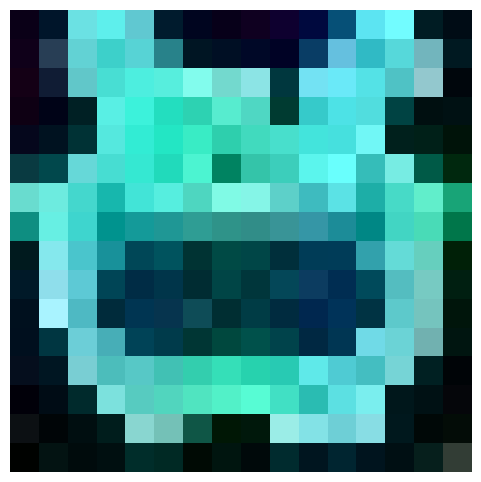

In [5]:
img = Image.open(os.path.join(IMAGE_DIR, os.listdir(IMAGE_DIR)[0]))
plt.figure(figsize=(6, 6))
plt.imshow(img, interpolation='nearest')
plt.axis('off')
plt.show()

## Table checking

In [6]:
table

,Image Index,Image Path,Label
0,1,path/to/image_1.jpg,[1. 0. 0. 0. 0.]
1,2,path/to/image_2.jpg,[0. 0. 0. 0. 1.]
2,3,path/to/image_3.jpg,[1. 0. 0. 0. 0.]
3,4,path/to/image_4.jpg,[0. 0. 0. 0. 1.]
4,5,path/to/image_5.jpg,[1. 0. 0. 0. 0.]
...,...,...,...
89395,89396,path/to/image_89396.jpg,[0. 0. 0. 1. 0.]
89396,89397,path/to/image_89397.jpg,[0. 0. 0. 1. 0.]
89397,89398,path/to/image_89398.jpg,[0. 0. 0. 1. 0.]
89398,89399,path/to/image_89399.jpg,[0. 0. 0. 1. 0.]


# Data preparing

In [7]:
table = table.drop("Image Index", axis=1)
table

,Image Path,Label
0,path/to/image_1.jpg,[1. 0. 0. 0. 0.]
1,path/to/image_2.jpg,[0. 0. 0. 0. 1.]
2,path/to/image_3.jpg,[1. 0. 0. 0. 0.]
3,path/to/image_4.jpg,[0. 0. 0. 0. 1.]
4,path/to/image_5.jpg,[1. 0. 0. 0. 0.]
...,...,...
89395,path/to/image_89396.jpg,[0. 0. 0. 1. 0.]
89396,path/to/image_89397.jpg,[0. 0. 0. 1. 0.]
89397,path/to/image_89398.jpg,[0. 0. 0. 1. 0.]
89398,path/to/image_89399.jpg,[0. 0. 0. 1. 0.]


In [8]:
def decrement_image_index(path: str) -> str:
    return re.sub(
        r'path/to/image_(\d+)\.jpg',
        lambda m: f"image_{int(m.group(1)) - 1}.JPEG",
        path
    )

table['Image Path'] = table['Image Path'].apply(decrement_image_index)
table

,Image Path,Label
0,image_0.JPEG,[1. 0. 0. 0. 0.]
1,image_1.JPEG,[0. 0. 0. 0. 1.]
2,image_2.JPEG,[1. 0. 0. 0. 0.]
3,image_3.JPEG,[0. 0. 0. 0. 1.]
4,image_4.JPEG,[1. 0. 0. 0. 0.]
...,...,...
89395,image_89395.JPEG,[0. 0. 0. 1. 0.]
89396,image_89396.JPEG,[0. 0. 0. 1. 0.]
89397,image_89397.JPEG,[0. 0. 0. 1. 0.]
89398,image_89398.JPEG,[0. 0. 0. 1. 0.]


In [9]:
table['Label'] = table['Label'].apply(
    lambda x: np.fromstring(x.strip("[]"), sep=' ').argmax()
)
table

,Image Path,Label
0,image_0.JPEG,0
1,image_1.JPEG,4
2,image_2.JPEG,0
3,image_3.JPEG,4
4,image_4.JPEG,0
...,...,...
89395,image_89395.JPEG,3
89396,image_89396.JPEG,3
89397,image_89397.JPEG,3
89398,image_89398.JPEG,3


# Data analysis

In [10]:
label_counts = (
    table['Label']
    .value_counts()
    .reset_index()
)
label_counts.columns = ['Label', 'Count']
label_counts['Percentage'] = (label_counts['Count'] / label_counts['Count'].sum()) * 100

fig = px.bar(
    label_counts,
    x='Label',
    y='Count',
    text=label_counts['Count'],
    title='Распределение классов',
    labels={'Label': 'Класс', 'Count': 'Количество'},
    color='Count',
    color_continuous_scale='Blues',
    hover_data={'Percentage': ':.2f%'}
)

fig.update_traces(
    textposition='outside',
    hovertemplate="<b>Класс:</b> %{x}<br><b>Количество:</b> %{y}<br><b>Доля:</b> %{customdata[0]:.2f}%<extra></extra>"
)

fig.update_layout(
    xaxis_title='Класс',
    yaxis_title='Количество',
)

fig.show()

/tmp/ipykernel_14015/3186769074.py:7: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  label_counts['Percentage'] = (label_counts['Count'] / label_counts['Count'].sum()) * 100


# Models

## Model building

In [11]:
class MlpModel(nn.Module):
    """Multilayer Perceptron (MLP) neural network for classification tasks.

    Attributes:
        input_module (nn.Sequential): Flattens the input and maps it to the
            first hidden layer dimension with an activation function.
        hidden_module (nn.Sequential): Sequential container of intermediate linear
            layers followed by activation functions.
        output_module (nn.Sequential): Final linear layer projecting hidden features
            to class logits.
    """

    def __init__(
            self,
            input_shape: Tuple[int, ...], 
            hidden_shape: List[int],
            output_shape: int,
            f_activation: Type[nn.Module] | Callable[[], nn.Module]
    ) -> None:
        """Initializes the layers and weights of the MLP model.

        Args:
            input_shape: Dimensions of a single input sample excluding batch dimension.
            hidden_shape: List specifying the number of units in each hidden layer. Must contain at least one element.
            output_shape: Number of output features or target classes.
            f_activation: Layer type or factory callable returning an activation module
        """

        super().__init__()
        
        self.input_module = nn.Sequential(
            nn.modules.flatten.Flatten(),
            nn.Linear(
                math.prod(input_shape),
                hidden_shape[0]
            ),
            f_activation()
        )                          
        self.hidden_module = nn.Sequential(
            *[nn.Sequential(
                nn.Linear(hidden_shape[i], hidden_shape[i + 1]),
                f_activation()
            ) for i in range(len(hidden_shape) - 1)]
        )
        self.output_module = nn.Sequential(
            nn.Linear(hidden_shape[-1], output_shape)
        )

        
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Performs the forward pass of the model.

        Args:
            x: Input tensor of shape (batch_size, *input_shape).

        Returns:
            torch.Tensor: Unnormalized raw logits of shape (batch_size, output_shape).
        """

        x = self.input_module(x)
        x = self.hidden_module(x)
        x = self.output_module(x)

        return x

## Dataset building

In [12]:
def create_dataset(table: pd.DataFrame, image_dir: str, transform: Optional[Callable[[Image.Image], torch.Tensor]] = None) -> TensorDataset:
    """Loads images from disk into memory and constructs a PyTorch TensorDataset.

    Args:BASE_DIR_NAME
        table: Pandas DataFrame containing at least 'Image Path' and 'Label' columns.
        image_dir: Path to the directory where image files are stored.
        transform: Optional callable or torchvision pipeline to preprocess and convert PIL Image instances into torch.Tensor objects.

    Returns:
        TensorDataset: A PyTorch dataset holding a stacked 4D tensor of features with shape (N, C, H, W) and a 1D tensor of class labels with shape (N,).
    """

    images_list = []
    
    for path in table['Image Path']:
        full_path = os.path.join(image_dir, os.path.basename(path))
        img = Image.open(full_path).convert('RGB')
        
        if transform is not None:
            img = transform(img)
            
        images_list.append(img)
    
    features_tensor = torch.stack(images_list)
    labels_tensor = torch.tensor(table['Label'].values, dtype=torch.long)
    
    return TensorDataset(features_tensor, labels_tensor)

## Data splitting

In [13]:
train_df, temp_df = train_test_split(
    table,
    test_size=0.90,
    random_state=42,
    stratify=table['Label']
)
valid_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df['Label']
)

train_df = train_df.reset_index(drop=True)
valid_df = valid_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

## Dataloader Building

In [14]:
BATCH_SIZE = 32

transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
])

train_loader = DataLoader(create_dataset(train_df, IMAGE_DIR, transform), batch_size=BATCH_SIZE, shuffle=True)
valid_loader = DataLoader(create_dataset(valid_df, IMAGE_DIR, transform), batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(create_dataset(test_df, IMAGE_DIR, transform), batch_size=BATCH_SIZE, shuffle=False)

## Model fitting

In [15]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def run_epoch(model: nn.Module, loader: DataLoader, loss_function: nn.Module, optimizer: Optional[torch.optim.Optimizer] = None) -> Tuple[float, float]:
    """Runs a single training or evaluation epoch over a DataLoader.

    Args:
        model: PyTorch neural network model to train or evaluate.
        loader: DataLoader providing batches of input images and corresponding labels.
        criterion: Loss function module.
        optimizer: Optimization algorithm instance.

    Returns:
        Tuple[float, float]: A tuple containing:
            - Average scalar loss over the entire epoch.
            - Classification accuracy as a fraction between 0.0 and 1.0.
    """

    is_train = optimizer is not None
    model.train() if is_train else model.eval()
    
    total_loss, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(is_train):
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = loss_function(outputs, labels)
            
            if is_train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
                
            total_loss += loss.item() * images.size(0)
            preds = outputs.argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += images.size(0)
            
    return total_loss / total, correct / total

def train_model(model: nn.Module, train_loader: DataLoader, valid_loader: DataLoader, epochs: int = 25, lr: float = 1e-3) -> Dict[str, List[float]]:
    """Trains a model across multiple epochs and evaluates it on validation data.

    Args:
        model: Neural network module to optimize.
        train_loader: DataLoader containing the training dataset batches.
        val_loader: DataLoader containing the validation dataset batches.
        epochs: Number of full training iterations over the dataset.
        lr: Learning rate parameter for the Adam optimizer.

    Returns:
        Dict[str, List[float]]: Training history dictionary mapping metric names ('train_loss', 'valid_loss', 'train_accuracy', 'valid_accuracy') to lists of their per-epoch values.
    """

    loss = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {'train_loss': [], 'valid_loss': [], 'train_accurancy': [], 'valid_accurancy': []}
    
    for _ in range(epochs):
        train_loss, train_accurancy = run_epoch(model, train_loader, loss, optimizer)
        valid_loss, valid_accurancy = run_epoch(model, valid_loader, loss)
        
        history['train_loss'].append(train_loss)
        history['valid_loss'].append(valid_loss)
        history['train_accurancy'].append(train_accurancy)
        history['valid_accurancy'].append(valid_accurancy)

    return history

In [16]:
model = MlpModel(
    input_shape=(3, 16, 16), 
    hidden_shape=[128, 64], 
    output_shape=table['Label'].nunique(),
    f_activation=nn.Sigmoid
).to(device)

history = train_model(model, train_loader, valid_loader, epochs=5, lr=1e-3)

## Validation



In [17]:
fig = make_subplots(rows=1, cols=2, subplot_titles=('Cross-Entropy Loss', 'Accuracy'))
epochs_range = list(range(1, 31))

fig.add_trace(go.Scatter(
    x=epochs_range, 
    y=history['train_loss'], 
    name='Train Loss',
    line=dict(color='blue')
), row=1, col=1
)
fig.add_trace(go.Scatter(
    x=epochs_range, 
    y=history['valid_loss'], 
    name='Valid Loss', 
    line=dict(color='orange')
), row=1, col=1)

fig.add_trace(go.Scatter(
    x=epochs_range, 
    y=history['train_accurancy'], 
    name='Train Accurancy', 
    line=dict(color='blue', dash='dot')
), row=1, col=2)
fig.add_trace(go.Scatter(
    x=epochs_range, 
    y=history['valid_accurancy'], 
    name='Valid Accurancy', 
    line=dict(color='orange', dash='dot')
), row=1, col=2)

fig.update_layout(title_text='MLP Fitting Dinamyc')
fig.show()

In [18]:
model.eval()

all_preds = []
all_targets = []

with torch.no_grad():
    for images, labels in valid_loader:
        images = images.to(device)
        
        outputs = model(images)
        preds = outputs.argmax(dim=1).cpu()
        
        all_preds.extend(preds.numpy())
        all_targets.extend(labels.numpy())

all_preds = np.array(all_preds)
all_targets = np.array(all_targets)

class_names = ['Hero', 'Non-hero', 'Food', 'Spell/Weapon', 'Side-facing']

acc = accuracy_score(all_targets, all_preds)
macro_f1 = f1_score(all_targets, all_preds, average='macro')
weighted_f1 = f1_score(all_targets, all_preds, average='weighted')

print(f"Accuracy: {acc}")
print(f"Macro F1-Score: {macro_f1}")
print(f"Weighted F1-Score: {weighted_f1}\n")

print(classification_report(all_targets, all_preds, target_names=class_names, digits=4))

cm = confusion_matrix(all_targets, all_preds)

fig_cm = px.imshow(
    cm,
    text_auto=True,
    labels=dict(x="Predicted Class", y="Actual Class", color="Count"),
    x=class_names,
    y=class_names,
    color_continuous_scale='Blues',
    title="Confusion Matrix"
)

fig_cm.update_layout(
    xaxis_title="Predicted Class",
    yaxis_title="Actual Class"
)
fig_cm.show()

Accuracy: 0.9974397216007954
Macro F1-Score: 0.9954591693790096
Weighted F1-Score: 0.9974190015434583

              precision    recall  f1-score   support

        Hero     1.0000    1.0000    1.0000      3600
    Non-hero     1.0000    1.0000    1.0000     14580
        Food     1.0000    0.9619    0.9806      2700
Spell/Weapon     0.9935    1.0000    0.9967     15750
 Side-facing     1.0000    1.0000    1.0000      3600

    accuracy                         0.9974     40230
   macro avg     0.9987    0.9924    0.9955     40230
weighted avg     0.9975    0.9974    0.9974     40230



## Experiment

In [19]:
experiments = {
    "Base (128-64)": [128, 64],
    "Narrow (32-16)": [32, 16],
    "Wide (512-256)": [512, 256],
    "Small (128)": [128],
    "Deep (128-128-64-32)": [128, 128, 64, 32]
}

num_classes = table['Label'].nunique()
results = []

for experiment_name, hidden_config in experiments.items():
    torch.manual_seed(42)
    
    model = MlpModel(
        (3, 16, 16),
        hidden_config,
        num_classes,
        nn.Tanh
    ).to(device)
    
    params_count = sum(p.numel() for p in model.parameters() if p.requires_grad)
    
    history = train_model(model, train_loader, valid_loader, epochs=5, lr=1e-3)
    test_loss, test_accurancy = run_epoch(model, test_loader, nn.CrossEntropyLoss())
    
    results.append({
        "Configuration": experiment_name,
        "Params Count": params_count,
        "Best Valid Accurancy": max(history['valid_accurancy']),
        "Final Valid Loss": history['valid_loss'][-1],
        "Test Accurancy": test_accurancy,
    })

comparison_df = pd.DataFrame(results).sort_values(by="Test Accurancy", ascending=False)
comparison_df


,Configuration,Params Count,Best Valid Accurancy,Final Valid Loss,Test Accurancy
0,Base (128-64),107013,0.999379,0.008003,0.999379
1,Narrow (32-16),25221,0.999379,0.012868,0.999379
2,Wide (512-256),526341,0.999379,0.009365,0.999379
3,Small (128),99077,0.999379,0.013439,0.999379
4,Deep (128-128-64-32),125445,0.995476,0.021105,0.995227


$$